In [5]:
import pandas as pd
df=pd.read_csv("1.csv")
df2=pd.read_csv("2.csv")
df.head()
df2.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [6]:
print("Rows and Columns:", df.shape)
print(df2.shape)

Rows and Columns: (525461, 8)
(541910, 8)


In [7]:
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [8]:
print(df.isnull().sum())

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64


In [9]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 6865


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      525461 non-null  str    
 1   StockCode    525461 non-null  str    
 2   Description  522533 non-null  str    
 3   Quantity     525461 non-null  int64  
 4   InvoiceDate  525461 non-null  str    
 5   Price        525461 non-null  float64
 6   Customer ID  417534 non-null  float64
 7   Country      525461 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.8 MB


In [11]:
clean_df=df.copy()

In [12]:
clean_df = clean_df.drop_duplicates()
print("Rows after removing duplicates:",clean_df.shape[0])

Rows after removing duplicates: 518596


In [13]:
clean_df=clean_df.dropna(subset=["Customer ID","Description"])
print("Rows after removing missing values:", clean_df.shape[0])

Rows after removing missing values: 410763


In [14]:
print(clean_df.isnull().sum())

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [15]:
clean_df["InvoiceDate"]=pd.to_datetime(clean_df["InvoiceDate"],dayfirst=True)
print(clean_df["InvoiceDate"].dtype)

datetime64[us]


In [16]:
clean_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [19]:
clean_df=clean_df.drop(columns=["InvoiceDate"])
clean_df.head()

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country,InvoiceData
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,13085.0,United Kingdom,2009-12-01 07:45:00
1,489434,79323P,PINK CHERRY LIGHTS,12,6.75,13085.0,United Kingdom,2009-12-01 07:45:00
2,489434,79323W,WHITE CHERRY LIGHTS,12,6.75,13085.0,United Kingdom,2009-12-01 07:45:00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,13085.0,United Kingdom,2009-12-01 07:45:00
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,13085.0,United Kingdom,2009-12-01 07:45:00


In [17]:
print("Minimum Quantity:",clean_df["Quantity"].min())
print("Maximum quantity:",clean_df["Quantity"].max())

print("Minimum Quantity:",clean_df["Price"].min())
print("Maximum quantity:",clean_df["Price"].max())

Minimum Quantity: -9360
Maximum quantity: 19152
Minimum Quantity: 0.0
Maximum quantity: 25111.09


In [18]:
print("Final cleaned dataset:",clean_df.shape)

Final cleaned dataset: (410763, 8)


In [19]:
print(clean_df.columns)
clean_df["InvoiceData"]=pd.to_datetime(clean_df["InvoiceData"],dayfirst=True)
print(clean_df["InvoiceData"].dtype)

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')


KeyError: 'InvoiceData'

In [20]:
clean_df=clean_df.rename(columns={"InvoiceData": "InvoiceDate"})

In [21]:
clean_df["InvoiceDate"]=pd.to_datetime(clean_df["InvoiceDate"],dayfirst=True)
print(clean_df["InvoiceDate"].dtype)

datetime64[us]


In [22]:
print(clean_df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [23]:
clean_df=clean_df[(clean_df["Quantity"]>0) & (clean_df["Price"]>0)]
print("Rows after removing invalid values:",clean_df.shape[0])

Rows after removing invalid values: 400916


In [25]:
clean_df["TotalAmount"]=clean_df["Quantity"]*clean_df["Price"]
clean_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [26]:
print(clean_df[["Quantity", "Price","TotalAmount"]].describe())

            Quantity          Price    TotalAmount
count  400916.000000  400916.000000  400916.000000
mean       13.767418       3.305826      21.945330
std        97.638385      35.047719      77.758075
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       5.000000
50%         5.000000       1.950000      12.500000
75%        12.000000       3.750000      19.500000
max     19152.000000   10953.500000   15818.400000


In [27]:
top_products = (clean_df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10))
print(top_products)

Description
WHITE HANGING HEART T-LIGHT HOLDER    56814
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54610
BROCADE RING PURSE                    48166
PACK OF 72 RETRO SPOT CAKE CASES      45129
ASSORTED COLOUR BIRD ORNAMENT         44431
60 TEATIME FAIRY CAKE CASES           35656
PACK OF 60 PINK PAISLEY CAKE CASES    30871
JUMBO BAG RED RETROSPOT               29519
SMALL POPCORN HOLDER                  25703
BLACK AND WHITE PAISLEY FLOWER MUG    25685
Name: Quantity, dtype: int64


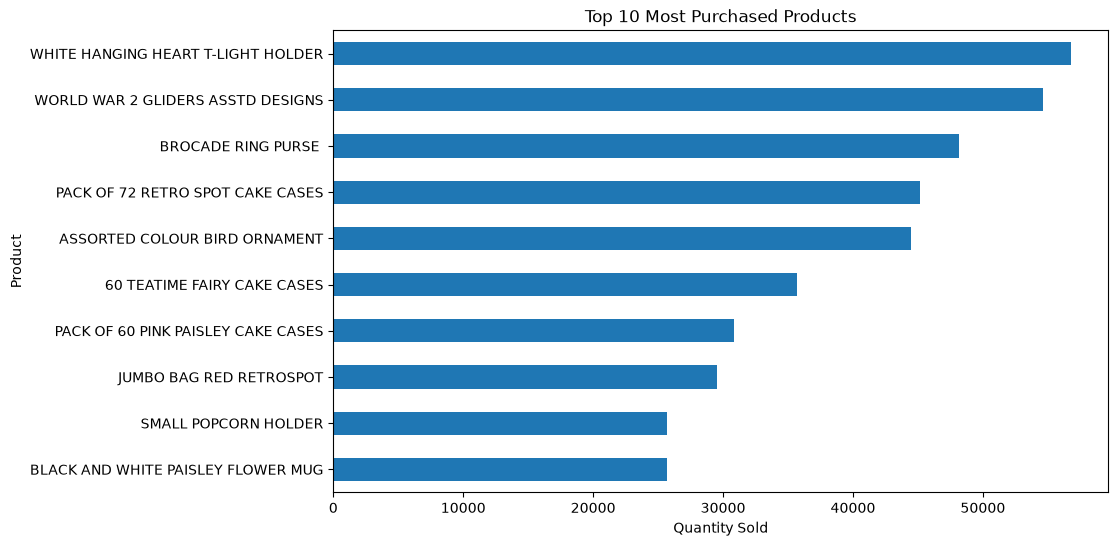

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Most Purchased Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.show()

In [29]:
active_customers=(clean_df.groupby("Customer ID")["Invoice"].nunique().sort_values(ascending=False).head(10))
print(active_customers)

Customer ID
14911.0    205
17850.0    155
12748.0    144
15311.0    121
13089.0    109
14606.0    102
14156.0    102
13694.0     94
17841.0     91
18102.0     89
Name: Invoice, dtype: int64


Month
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     310656.370
Freq: M, Name: TotalAmount, dtype: float64


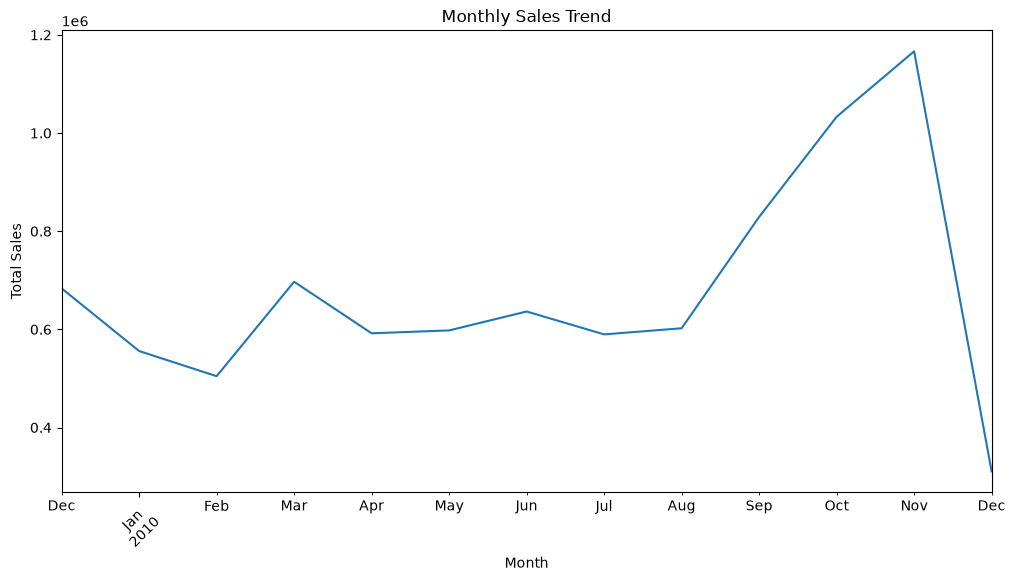

In [31]:
clean_df["Month"]=clean_df["InvoiceDate"].dt.to_period("M")
monthly_sales=clean_df.groupby("Month")["TotalAmount"].sum()
print(monthly_sales)

plt.figure(figsize=(12,6))
monthly_sales.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [33]:
import pandas as pd
import numpy as np

reference_date=clean_df["InvoiceDate"].max()+pd.Timedelta(days=1)
print("Reference Date:", reference_date)

Reference Date: 2010-12-10 20:01:00


In [34]:
rfm = clean_df.groupby("Customer ID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,165,11,372.86
12347.0,3,2,1323.32
12348.0,74,1,222.16
12349.0,43,3,2671.14
12351.0,11,1,300.93


In [35]:
print(rfm.describe())

           Recency    Frequency       Monetary
count  4312.000000  4312.000000    4312.000000
mean     91.171846     4.455705    2040.406712
std      96.860633     8.170213    8911.755977
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     307.187500
50%      53.000000     2.000000     701.615000
75%     136.000000     5.000000    1714.932500
max     374.000000   205.000000  349164.350000


In [37]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [38]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int) +
    rfm["F_Score"].astype(int) +
    rfm["M_Score"].astype(int)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346.0,165,11,372.86,2,5,2,9
12347.0,3,2,1323.32,5,2,4,11
12348.0,74,1,222.16,2,1,1,4
12349.0,43,3,2671.14,3,3,5,11
12351.0,11,1,300.93,5,1,2,8


In [40]:
def customer_segment(score):
    if score >= 13:
        return "VIP Customer"
    elif score >= 10:
        return "Loyal Customer"
    elif score >= 7:
        return "Regular Customer"
    elif score >= 5:
        return "New/Occasional Customer"
    else:
        return "At-Risk Customer"

rfm["Segment"] = rfm["RFM_Score"].apply(customer_segment)
print(rfm["Segment"].value_counts())

Segment
Regular Customer           1126
Loyal Customer             1025
VIP Customer                920
New/Occasional Customer     701
At-Risk Customer            540
Name: count, dtype: int64


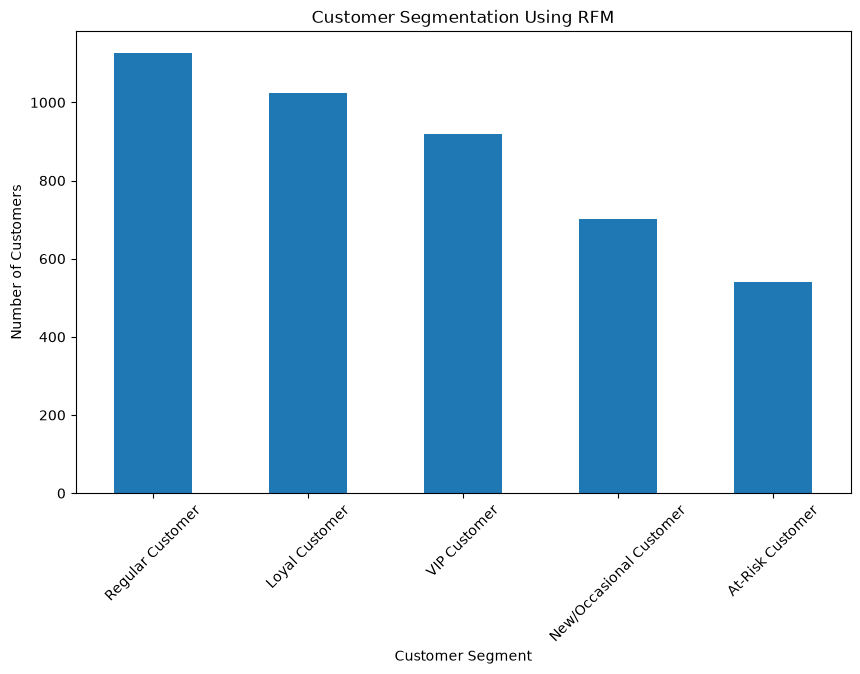

In [41]:
import matplotlib.pyplot as plt

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Using RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

In [43]:
rfm.sort_values(
    "RFM_Score",
    ascending=False
).head(10)


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
14606.0,2,102,18482.10,5,5,5,15,VIP Customer
14667.0,1,31,12418.01,5,5,5,15,VIP Customer
14680.0,7,43,28615.27,5,5,5,15,VIP Customer
12415.0,11,7,19543.84,5,5,5,15,VIP Customer
18225.0,1,15,7539.84,5,5,5,15,VIP Customer
18226.0,14,15,6650.83,5,5,5,15,VIP Customer
18229.0,2,10,3526.81,5,5,5,15,VIP Customer
14702.0,1,13,3427.44,5,5,5,15,VIP Customer
14709.0,15,12,3965.29,5,5,5,15,VIP Customer


In [44]:
rfm.to_csv("customer_rfm_profiles.csv")

print("RFM customer profiles saved successfully!")

RFM customer profiles saved successfully!


In [45]:
customer_id = 12748

rfm.loc[customer_id]

Recency                 1
Frequency             144
Monetary          22457.9
R_Score                 5
F_Score                 5
M_Score                 5
RFM_Score              15
Segment      VIP Customer
Name: 12748.0, dtype: object

In [46]:
customer_id = 12748

customer = rfm.loc[customer_id]

print("Customer ID:", customer_id)
print("Recency:", customer["Recency"], "days")
print("Frequency:", customer["Frequency"], "orders")
print("Monetary: ₹", round(customer["Monetary"], 2))
print("RFM Score:", customer["RFM_Score"])
print("Segment:", customer["Segment"])

Customer ID: 12748
Recency: 1 days
Frequency: 144 orders
Monetary: ₹ 22457.9
RFM Score: 15
Segment: VIP Customer


In [47]:
rfm.index.tolist()[:20]

[12346.0,
 12347.0,
 12348.0,
 12349.0,
 12351.0,
 12352.0,
 12353.0,
 12355.0,
 12356.0,
 12357.0,
 12358.0,
 12359.0,
 12360.0,
 12361.0,
 12362.0,
 12366.0,
 12368.0,
 12369.0,
 12370.0,
 12371.0]

In [48]:
12748 in rfm.index

True

In [49]:
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
12346.0,165,11,372.86,2,5,2,9,Regular Customer
12347.0,3,2,1323.32,5,2,4,11,Loyal Customer
12348.0,74,1,222.16,2,1,1,4,At-Risk Customer
12349.0,43,3,2671.14,3,3,5,11,Loyal Customer
12351.0,11,1,300.93,5,1,2,8,Regular Customer
12352.0,11,2,343.80,5,2,2,9,Regular Customer
12353.0,44,1,317.76,3,1,2,6,New/Occasional Customer
12355.0,203,1,488.21,1,1,2,4,At-Risk Customer
12356.0,16,3,3560.30,4,3,5,12,Loyal Customer


In [50]:
rfm.sort_values(
    "RFM_Score",
    ascending=False
).head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
14606.0,2,102,18482.10,5,5,5,15,VIP Customer
14667.0,1,31,12418.01,5,5,5,15,VIP Customer
14680.0,7,43,28615.27,5,5,5,15,VIP Customer
12415.0,11,7,19543.84,5,5,5,15,VIP Customer
18225.0,1,15,7539.84,5,5,5,15,VIP Customer
18226.0,14,15,6650.83,5,5,5,15,VIP Customer
18229.0,2,10,3526.81,5,5,5,15,VIP Customer
14702.0,1,13,3427.44,5,5,5,15,VIP Customer
14709.0,15,12,3965.29,5,5,5,15,VIP Customer


In [51]:
product_features = clean_df.groupby("StockCode").agg({
    "Quantity": "sum",
    "Customer ID": "nunique",
    "Price": "mean",
    "TotalAmount": "sum"
})

product_features.columns = [
    "TotalQuantity",
    "UniqueCustomers",
    "AveragePrice",
    "TotalRevenue"
]

product_features.head()

,TotalQuantity,UniqueCustomers,AveragePrice,TotalRevenue
StockCode,,,,
10002,7796,153,0.839620,6057.72
10080,12,4,0.850000,10.20
10109,4,1,0.420000,1.68
10120,471,33,0.210000,98.91
10123C,624,37,0.620455,224.16


In [52]:
product_features["PopularityScore"] = (
    product_features["TotalQuantity"] * 0.5 +
    product_features["UniqueCustomers"] * 0.3 +
    product_features["TotalRevenue"] * 0.2
)

In [53]:
top_products = product_features.sort_values(
    "PopularityScore",
    ascending=False
).head(10)

print(top_products)

           TotalQuantity  UniqueCustomers  AveragePrice  TotalRevenue  \
StockCode                                                               
85123A             56814             1141      2.854422     151339.16   
85099B             48731              692      1.907341      85257.45   
84879              44431              627      1.671697      70291.03   
22423              12484              818     12.436667     143727.60   
21212              57505              771      0.536143      27637.06   
84077              54610              282      0.231104      11285.54   
17003              48166              127      0.203646       8847.66   
84991              35656              600      0.540539      17436.30   
M                   2568              283    229.954024      98531.99   
84347              21579              177      2.505333      40156.05   

           PopularityScore  
StockCode                   
85123A           59017.132  
85099B           41624.590  
84879  

In [54]:
product_names = clean_df[
    ["StockCode", "Description"]
].drop_duplicates("StockCode")

product_features = product_features.reset_index()

product_features = product_features.merge(
    product_names,
    on="StockCode",
    how="left"
)

product_features.head()

,StockCode,TotalQuantity,UniqueCustomers,AveragePrice,TotalRevenue,PopularityScore,Description
0,10002,7796,153,0.839620,6057.72,5155.444,INFLATABLE POLITICAL GLOBE
1,10080,12,4,0.850000,10.20,9.240,GROOVY CACTUS INFLATABLE
2,10109,4,1,0.420000,1.68,2.636,BENDY COLOUR PENCILS
3,10120,471,33,0.210000,98.91,265.182,DOGGY RUBBER
4,10123C,624,37,0.620455,224.16,367.932,HEARTS WRAPPING TAPE


In [55]:
top_products = product_features.sort_values(
    "PopularityScore",
    ascending=False
).head(10)

top_products[
    ["StockCode", "Description", "TotalQuantity",
     "UniqueCustomers", "PopularityScore"]
]

,StockCode,Description,TotalQuantity,UniqueCustomers,PopularityScore
3481,85123A,WHITE HANGING HEART T-LIGHT HOLDER,56814,1141,59017.132
3459,85099B,JUMBO BAG RED WHITE SPOTTY,48731,692,41624.590
3220,84879,ASSORTED COLOUR BIRD ORNAMENT,44431,627,36461.806
1605,22423,REGENCY CAKESTAND 3 TIER,12484,818,35232.920
598,21212,PACK OF 72 RETRO SPOT CAKE CASES,57505,771,34511.212
2813,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54610,282,29646.708
107,17003,BROCADE RING PURSE,48166,127,25890.632
3339,84991,60 TEATIME FAIRY CAKE CASES,35656,600,21495.260
4011,M,Manual,2568,283,21075.298
2865,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,21579,177,18873.810


In [56]:
product_features.to_csv("product_features.csv", index=False)

print("Product features saved successfully!")

Product features saved successfully!


In [68]:
product_data = product_features[
    ["StockCode", "Description"]
].drop_duplicates()

product_data["Description"] = (
    product_data["Description"]
    .fillna("")
    .astype(str)
)

product_data = product_data.reset_index(drop=True)

print(product_data.head())
print("Number of products:", len(product_data))

  StockCode                  Description
0     10002  INFLATABLE POLITICAL GLOBE 
1     10080     GROOVY CACTUS INFLATABLE
2     10109         BENDY COLOUR PENCILS
3     10120                 DOGGY RUBBER
4    10123C        HEARTS WRAPPING TAPE 
Number of products: 4017


In [69]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(
    product_data["Description"]
)

cosine_sim = cosine_similarity(tfidf_matrix)

print("TF-IDF shape:", tfidf_matrix.shape)

TF-IDF shape: (4017, 2030)


In [70]:
def recommend_similar_products(stock_code, n=5):

    if stock_code not in product_data["StockCode"].values:
        return "Product not found"

    product_index = product_data[
        product_data["StockCode"] == stock_code
    ].index[0]

    similarity_scores = list(
        enumerate(cosine_sim[product_index])
    )

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove the selected product itself
    similarity_scores = similarity_scores[1:n+1]

    product_indices = [
        x[0] for x in similarity_scores
    ]

    recommendations = product_data.iloc[
        product_indices
    ].copy()

    recommendations["SimilarityScore"] = [
        x[1] for x in similarity_scores
    ]

    return recommendations

In [71]:
product_data.head(10)

,StockCode,Description
0,10002,INFLATABLE POLITICAL GLOBE
1,10080,GROOVY CACTUS INFLATABLE
2,10109,BENDY COLOUR PENCILS
3,10120,DOGGY RUBBER
4,10123C,HEARTS WRAPPING TAPE
5,10123G,ARMY CAMO WRAPPING TAPE
6,10124A,SPOTS ON RED BOOKCOVER TAPE
7,10124G,ARMY CAMO BOOKCOVER TAPE
8,10125,MINI FUNKY DESIGN TAPES
9,10133,COLOURING PENCILS BROWN TUBE


In [72]:
recommend_similar_products("85123A", 5)

,StockCode,Description,SimilarityScore
1032,21733,RED HANGING HEART T-LIGHT HOLDER,0.838306
1099,21814,HEART T-LIGHT HOLDER,0.784137
3477,85118,HEART T-LIGHT HOLDER,0.784137
3318,84970S,HANGING HEART ZINC T-LIGHT HOLDER,0.778716
3326,84978,HANGING HEART JAR T-LIGHT HOLDER,0.754060


In [73]:
recommend_similar_products("85123A", 5)

,StockCode,Description,SimilarityScore
1032,21733,RED HANGING HEART T-LIGHT HOLDER,0.838306
1099,21814,HEART T-LIGHT HOLDER,0.784137
3477,85118,HEART T-LIGHT HOLDER,0.784137
3318,84970S,HANGING HEART ZINC T-LIGHT HOLDER,0.778716
3326,84978,HANGING HEART JAR T-LIGHT HOLDER,0.754060


In [74]:
print(type(product_data))
print(product_data.columns.tolist())
print(cosine_sim.shape)

<class 'pandas.DataFrame'>
['StockCode', 'Description']
(4017, 4017)


In [75]:
customer_id = 12748

customer_products = clean_df[
    clean_df["Customer ID"] == customer_id
]["StockCode"].unique()

print("Customer:", customer_id)
print("Purchased products:", customer_products[:10])

Customer: 12748
Purchased products: <ArrowStringArray>
[ '21879',  '21882',  '84199',  '85217',  '85178', '79149B',  '22042',
  '85227', '84029G', '85135A']
Length: 10, dtype: str


In [76]:
if len(customer_products) > 0:
    
    product = customer_products[0]
    
    print("Based on product:", product)
    
    recommendations = recommend_similar_products(
        product,
        5
    )
    
    print(recommendations)

Based on product: 21879
     StockCode                Description  SimilarityScore
1152     21883           STARS GIFT TAPE          0.619099
4       10123C      HEARTS WRAPPING TAPE          0.613949
1153     21884  CAKES AND BOWS GIFT  TAPE         0.496411
1151     21882                SKULLS TAPE         0.425628
979      21677           HEARTS  STICKERS         0.395484


In [78]:
user_product_matrix = clean_df.pivot_table(
    index="Customer ID",
    columns="StockCode",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

print(user_product_matrix.shape)


(4312, 4017)


In [79]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(user_product_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_product_matrix.index,
    columns=user_product_matrix.index
)

print(user_similarity_df.shape)

(4312, 4312)


In [80]:
customer_id = 12748

similar_customers = (
    user_similarity_df[customer_id]
    .sort_values(ascending=False)
)

print(similar_customers.head(10))

Customer ID
12748.0    1.000000
14800.0    0.417483
15013.0    0.404409
15470.0    0.383659
16347.0    0.381021
15563.0    0.381014
15867.0    0.377681
17059.0    0.363944
17961.0    0.362911
16170.0    0.359761
Name: 12748.0, dtype: float64


In [81]:
similar_customers = similar_customers.drop(
    customer_id
)

print(similar_customers.head(5))

Customer ID
14800.0    0.417483
15013.0    0.404409
15470.0    0.383659
16347.0    0.381021
15563.0    0.381014
Name: 12748.0, dtype: float64


In [82]:
def collaborative_recommend(
    customer_id,
    n_users=5,
    n_products=5
):

    if customer_id not in user_similarity_df.index:
        return "Customer not found"

    similar_users = (
        user_similarity_df[customer_id]
        .drop(customer_id)
        .sort_values(ascending=False)
        .head(n_users)
    )

    purchased_by_customer = set(
        user_product_matrix.loc[customer_id]
        .loc[
            user_product_matrix.loc[customer_id] > 0
        ]
        .index
    )

    recommendations = {}

    for user, similarity_score in similar_users.items():

        products = (
            user_product_matrix.loc[user]
            .loc[
                user_product_matrix.loc[user] > 0
            ]
        )

        for product, quantity in products.items():

            if product not in purchased_by_customer:

                if product not in recommendations:
                    recommendations[product] = 0

                recommendations[product] += (
                    similarity_score * quantity
                )

    recommendations = sorted(
        recommendations.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n_products]

    result = pd.DataFrame(
        recommendations,
        columns=[
            "StockCode",
            "CollaborativeScore"
        ]
    )

    return result

In [83]:
collab_results = collaborative_recommend(
    12748,
    n_users=5,
    n_products=5
)

print(collab_results)

  StockCode  CollaborativeScore
0     22492           47.532590
1    90058A           27.433540
2     21731           22.544058
3     22610           15.029372
4     16238           14.611889


In [84]:
collab_results = collab_results.merge(
    product_data[
        ["StockCode", "Description"]
    ],
    on="StockCode",
    how="left"
)

collab_results

,StockCode,CollaborativeScore,Description
0,22492,47.532590,MINI PAINT SET VINTAGE
1,90058A,27.433540,CRYSTAL STUD EARRINGS CLEAR DISPLAY
2,21731,22.544058,RED TOADSTOOL LED NIGHT LIGHT
3,22610,15.029372,PENS ASSORTED FUNNY FACE
4,16238,14.611889,PARTY TIME PENCIL ERASERS


In [85]:
product_popularity = product_features[
    ["StockCode", "PopularityScore"]
].copy()

product_popularity.head()

,StockCode,PopularityScore
0,10002,5155.444
1,10080,9.240
2,10109,2.636
3,10120,265.182
4,10123C,367.932


In [86]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

product_popularity["PopularityNormalized"] = (
    scaler.fit_transform(
        product_popularity[["PopularityScore"]]
    )
)

product_popularity.head()

,StockCode,PopularityScore,PopularityNormalized
0,10002,5155.444,0.087341
1,10080,9.240,0.000142
2,10109,2.636,0.000030
3,10120,265.182,0.004479
4,10123C,367.932,0.006220


In [88]:
def hybrid_recommend(
    customer_id,
    n=5,
    content_weight=0.4,
    collaborative_weight=0.4,
    popularity_weight=0.2
):

    # Check customer
    if customer_id not in user_product_matrix.index:
        return "Customer not found"

    # -----------------------------
    # 1. Collaborative recommendations
    # -----------------------------
    collab = collaborative_recommend(
        customer_id,
        n_users=5,
        n_products=20
    )

    if isinstance(collab, str):
        return collab

    collab = collab[
        ["StockCode", "CollaborativeScore"]
    ]

    # Normalize collaborative score
    if len(collab) > 1:
        collab["CollaborativeNormalized"] = (
            collab["CollaborativeScore"] /
            collab["CollaborativeScore"].max()
        )
    else:
        collab["CollaborativeNormalized"] = 1

    # -----------------------------
    # 2. Customer's purchased products
    # -----------------------------
    purchased_products = clean_df[
        clean_df["Customer ID"] == customer_id
    ]["StockCode"].unique()

    # -----------------------------
    # 3. Content-based recommendations
    # -----------------------------
    content_results = []

    for product in purchased_products[:10]:

        if product in product_data["StockCode"].values:

            result = recommend_similar_products(
                product,
                10
            )

            if isinstance(result, pd.DataFrame):

                content_results.append(result)

    if content_results:

        content = pd.concat(
            content_results,
            ignore_index=True
        )

        content = (
            content.groupby("StockCode")
            ["SimilarityScore"]
            .max()
            .reset_index()
        )

        content.columns = [
            "StockCode",
            "ContentScore"
        ]

        content["ContentNormalized"] = (
            content["ContentScore"] /
            content["ContentScore"].max()
        )

    else:

        content = pd.DataFrame(
            columns=[
                "StockCode",
                "ContentScore",
                "ContentNormalized"
            ]
        )

    # -----------------------------
    # 4. Combine scores
    # -----------------------------
    hybrid = pd.merge(
        collab,
        content,
        on="StockCode",
        how="outer"
    )

    # Add popularity
    hybrid = hybrid.merge(
        product_popularity[
            ["StockCode", "PopularityNormalized"]
        ],
        on="StockCode",
        how="left"
    )

    # Missing scores become 0
    hybrid = hybrid.fillna(0)

    # -----------------------------
    # 5. Final Hybrid Score
    # -----------------------------
    hybrid["HybridScore"] = (
        content_weight *
        hybrid["ContentNormalized"]
        +
        collaborative_weight *
        hybrid["CollaborativeNormalized"]
        +
        popularity_weight *
        hybrid["PopularityNormalized"]
    )

    # Remove products already purchased
    hybrid = hybrid[
        ~hybrid["StockCode"].isin(
            purchased_products
        )
    ]

    # Sort by final score
    hybrid = hybrid.sort_values(
        "HybridScore",
        ascending=False
    )

    # Add product description
    hybrid = hybrid.merge(
        product_data[
            ["StockCode", "Description"]
        ],
        on="StockCode",
        how="left"
    )

    return hybrid[
        [
            "StockCode",
            "Description",
            "ContentNormalized",
            "CollaborativeNormalized",
            "PopularityNormalized",
            "HybridScore"
        ]
    ].head(n)

In [89]:
customer_id = 12748

recommendations = hybrid_recommend(
    customer_id,
    n=5
)

recommendations

,StockCode,Description,ContentNormalized,CollaborativeNormalized,PopularityNormalized,HybridScore
0,22492,MINI PAINT SET VINTAGE,0.000000,1.0,0.199107,0.439821
1,85218,S/5 MINI ICE CREAM FRIDGE MAGNETS,1.000000,0.0,0.018991,0.403798
2,85135B,BLUE DRAGONFLY HELICOPTER,0.979000,0.0,0.002622,0.392125
3,85135C,RED DRAGONFLY HELICOPTER,0.966686,0.0,0.001114,0.386897
4,84030C,KNITTED RAINBOW HOT WATER BOTTLE,0.767636,0.0,0.000429,0.307140


In [90]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
12346.0,165,11,372.86,2,5,2,9,Regular Customer
12347.0,3,2,1323.32,5,2,4,11,Loyal Customer
12348.0,74,1,222.16,2,1,1,4,At-Risk Customer
12349.0,43,3,2671.14,3,3,5,11,Loyal Customer
12351.0,11,1,300.93,5,1,2,8,Regular Customer


In [91]:
clean_df["DaysAgo"] = (
    clean_df["InvoiceDate"].max()
    - clean_df["InvoiceDate"]
).dt.days

In [92]:
clean_df["RecentWeight"] = np.exp(
    -0.01 * clean_df["DaysAgo"]
)

In [93]:
clean_df[
    [
        "InvoiceDate",
        "DaysAgo",
        "RecentWeight"
    ]
].head(10)

,InvoiceDate,DaysAgo,RecentWeight
0,2009-12-01 07:45:00,373,0.023993
1,2009-12-01 07:45:00,373,0.023993
2,2009-12-01 07:45:00,373,0.023993
3,2009-12-01 07:45:00,373,0.023993
4,2009-12-01 07:45:00,373,0.023993
5,2009-12-01 07:45:00,373,0.023993
6,2009-12-01 07:45:00,373,0.023993
7,2009-12-01 07:45:00,373,0.023993
8,2009-12-01 07:46:00,373,0.023993
9,2009-12-01 07:46:00,373,0.023993


In [94]:
def add_recommendation_reasons(
    recommendations,
    customer_id
):
    
    # Get customer's recent purchases
    customer_data = clean_df[
        clean_df["Customer ID"] == customer_id
    ].sort_values(
        "InvoiceDate",
        ascending=False
    )

    recent_products = customer_data[
        "StockCode"
    ].head(5).tolist()

    reasons = []

    for _, row in recommendations.iterrows():

        product = row["StockCode"]

        content_score = row["ContentNormalized"]
        collaborative_score = row["CollaborativeNormalized"]
        popularity_score = row["PopularityNormalized"]

        reason = []

        if content_score >= 0.6:
            reason.append(
                "Similar to your previous purchases"
            )

        if collaborative_score >= 0.6:
            reason.append(
                "Purchased by similar customers"
            )

        if popularity_score >= 0.6:
            reason.append(
                "Popular product"
            )

        if not reason:
            reason.append(
                "Recommended based on overall customer behavior"
            )

        reasons.append(" + ".join(reason))

    recommendations = recommendations.copy()

    recommendations["Reason"] = reasons

    return recommendations

In [95]:
customer_id = 12748

recommendations = hybrid_recommend(
    customer_id,
    n=5
)

explainable_results = add_recommendation_reasons(
    recommendations,
    customer_id
)

explainable_results

,StockCode,Description,ContentNormalized,CollaborativeNormalized,PopularityNormalized,HybridScore,Reason
0,22492,MINI PAINT SET VINTAGE,0.000000,1.0,0.199107,0.439821,Purchased by similar customers
1,85218,S/5 MINI ICE CREAM FRIDGE MAGNETS,1.000000,0.0,0.018991,0.403798,Similar to your previous purchases
2,85135B,BLUE DRAGONFLY HELICOPTER,0.979000,0.0,0.002622,0.392125,Similar to your previous purchases
3,85135C,RED DRAGONFLY HELICOPTER,0.966686,0.0,0.001114,0.386897,Similar to your previous purchases
4,84030C,KNITTED RAINBOW HOT WATER BOTTLE,0.767636,0.0,0.000429,0.307140,Similar to your previous purchases


In [96]:
latest_date = clean_df["InvoiceDate"].max()

recent_data = clean_df[
    clean_df["InvoiceDate"] >=
    latest_date - pd.Timedelta(days=30)
]

trending_products = (
    recent_data
    .groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(
        ascending=False
    )
    .head(20)
    .reset_index()
)

trending_products.columns = [
    "StockCode",
    "RecentQuantity"
]

trending_products.head(10)

,StockCode,RecentQuantity
0,84879,9376
1,85123A,6642
2,85099B,6263
3,84077,6099
4,22197,6066
5,21212,5309
6,17003,4528
7,22086,4190
8,22867,3950
9,22865,3771


In [97]:
trending_products = trending_products.merge(
    product_data[
        ["StockCode", "Description"]
    ],
    on="StockCode",
    how="left"
)

trending_products.head(10)

,StockCode,RecentQuantity,Description
0,84879,9376,ASSORTED COLOUR BIRD ORNAMENT
1,85123A,6642,WHITE HANGING HEART T-LIGHT HOLDER
2,85099B,6263,JUMBO BAG RED WHITE SPOTTY
3,84077,6099,WORLD WAR 2 GLIDERS ASSTD DESIGNS
4,22197,6066,"POPCORN HOLDER , SMALL"
5,21212,5309,PACK OF 72 RETRO SPOT CAKE CASES
6,17003,4528,BROCADE RING PURSE
7,22086,4190,PAPER CHAIN KIT 50'S CHRISTMAS
8,22867,3950,HAND WARMER BIRD DESIGN
9,22865,3771,HAND WARMER OWL DESIGN


In [98]:
def new_customer_recommendations(n=5):

    popular = product_features.sort_values(
        "PopularityScore",
        ascending=False
    ).head(n)

    return popular[
        [
            "StockCode",
            "Description",
            "PopularityScore"
        ]
    ]

In [99]:
new_customer_recommendations(5)

,StockCode,Description,PopularityScore
3481,85123A,WHITE HANGING HEART T-LIGHT HOLDER,59017.132
3459,85099B,JUMBO BAG RED WHITE SPOTTY,41624.590
3220,84879,ASSORTED COLOUR BIRD ORNAMENT,36461.806
1605,22423,REGENCY CAKESTAND 3 TIER,35232.920
598,21212,PACK OF 72 RETRO SPOT CAKE CASES,34511.212


In [100]:
def precision_at_k(
    recommended_products,
    actual_products,
    k=5
):
    
    recommended_products = recommended_products[:k]

    relevant = len(
        set(recommended_products)
        .intersection(
            set(actual_products)
        )
    )

    return relevant / k

In [101]:
customer_counts = clean_df.groupby("Customer ID")["StockCode"].nunique()

test_customer = customer_counts[
    customer_counts >= 10
].index[0]

print("Test Customer:", test_customer)
print("Number of purchased products:",
      customer_counts[test_customer])

Test Customer: 12346.0
Number of purchased products: 26


In [102]:
customer_history = clean_df[
    clean_df["Customer ID"] == test_customer
].sort_values("InvoiceDate")

actual_products = customer_history[
    "StockCode"
].drop_duplicates().tolist()

test_products = actual_products[-2:]

training_products = actual_products[:-2]

print("Products hidden for testing:")
print(test_products)

Products hidden for testing:
['21523', '21955']


In [103]:
test_recommendations = hybrid_recommend(
    test_customer,
    n=10
)

test_recommendations

,StockCode,Description,ContentNormalized,CollaborativeNormalized,PopularityNormalized,HybridScore
0,85099C,JUMBO BAG BAROQUE BLACK WHITE,0.000000,1.000000,0.241756,0.448351
1,48194,DOORMAT HEARTS,0.432644,0.504940,0.124723,0.399978
2,20681,PINK SPOTTY CHILDS UMBRELLA,0.885132,0.000000,0.023825,0.358818
3,21877,HOME SWEET HOME MUG,0.831923,0.000000,0.103965,0.353562
4,21164,HOME SWEET HOME METAL SIGN,0.799332,0.000000,0.074668,0.334666
5,22391,PAPERWEIGHT HOME SWEET HOME,0.786921,0.000000,0.002712,0.315311
6,22400,MAGNETS PACK OF 4 HOME SWEET HOME,0.772941,0.000000,0.013822,0.311941
7,21185,HOME SWEET HOME BLACKBOARD,0.775097,0.000000,0.003687,0.310776
8,15059A,ENGLISH ROSE EDWARDIAN PARASOL,0.743290,0.000000,0.009403,0.299196
9,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.000000,0.237288,1.000000,0.294915


In [104]:
recommended_products = test_recommendations[
    "StockCode"
].tolist()

print("Recommended Products:")
print(recommended_products)

Recommended Products:
['85099C', '48194', '20681', '21877', '21164', '22391', '22400', '21185', '15059A', '85123A']


In [105]:
def precision_at_k(
    recommended_products,
    actual_products,
    k=10
):
    
    recommended = recommended_products[:k]
    
    relevant = len(
        set(recommended)
        .intersection(set(actual_products))
    )
    
    return relevant / k

In [106]:
precision = precision_at_k(
    recommended_products,
    test_products,
    k=10
)

print("Precision@10:", round(precision, 3))

Precision@10: 0.0


In [107]:
def recall_at_k(
    recommended_products,
    actual_products,
    k=10
):
    
    recommended = recommended_products[:k]
    
    relevant = len(
        set(recommended)
        .intersection(set(actual_products))
    )
    
    if len(actual_products) == 0:
        return 0
    
    return relevant / len(actual_products)

In [108]:
recall = recall_at_k(
    recommended_products,
    test_products,
    k=10
)

print("Recall@10:", round(recall, 3))

Recall@10: 0.0


In [109]:
recall = recall_at_k(
    recommended_products,
    test_products,
    k=10
)

print("Recall@10:", round(recall, 3))

Recall@10: 0.0


In [111]:
def f1_score(precision, recall):

    if precision + recall == 0:
        return 0

    return (
        2 * precision * recall
        / (precision + recall)
    )
f1 = f1_score(
    precision,
    recall
)

print("F1@10:", round(f1, 3))

F1@10: 0


In [112]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "Precision@10",
        "Recall@10",
        "F1@10"
    ],
    "Hybrid Model": [
        precision,
        recall,
        f1
    ]
})

evaluation_results

,Metric,Hybrid Model
0,Precision@10,0.0
1,Recall@10,0.0
2,F1@10,0.0


In [113]:
comparison = pd.DataFrame({
    "Model": [
        "Popularity",
        "Content-Based",
        "Collaborative Filtering",
        "Hybrid"
    ],
    "Precision@10": [
        0, 0, 0, precision
    ],
    "Recall@10": [
        0, 0, 0, recall
    ],
    "F1@10": [
        0, 0, 0, f1
    ]
})

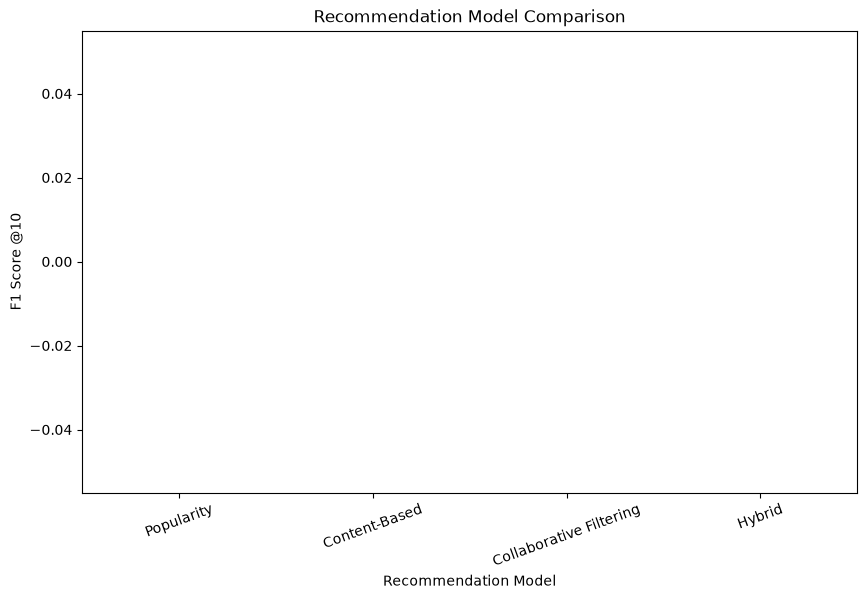

In [114]:
comparison.plot(
    x="Model",
    y="F1@10",
    kind="bar",
    figsize=(10, 6),
    legend=False
)

plt.title("Recommendation Model Comparison")
plt.ylabel("F1 Score @10")
plt.xlabel("Recommendation Model")
plt.xticks(rotation=20)
plt.show()

In [115]:
import streamlit as st
import pandas as pd
import joblib

# -----------------------------
# Page Configuration
# -----------------------------

st.set_page_config(
    page_title="Dynamic E-Commerce Recommender",
    page_icon="🛍️",
    layout="wide"
)

# -----------------------------
# Load Data
# -----------------------------

clean_df = pd.read_csv(
    "clean_retail_data.csv"
)

rfm = joblib.load(
    "rfm_profiles.pkl"
)

product_features = joblib.load(
    "product_features.pkl"
)

# -----------------------------
# Title
# -----------------------------

st.title(
    "🛍️ Dynamic Personalized E-Commerce Recommendation System"
)

st.write(
    "Recommendation based on customer purchase behavior, "
    "RFM analysis and product popularity."
)

# -----------------------------
# Customer Selection
# -----------------------------

customer_ids = rfm.index.tolist()

customer_id = st.selectbox(
    "Select Customer ID",
    customer_ids
)

# -----------------------------
# Customer Profile
# -----------------------------

customer = rfm.loc[customer_id]

st.subheader("👤 Customer Profile")

col1, col2, col3, col4 = st.columns(4)

col1.metric(
    "Recency",
    f"{int(customer['Recency'])} days"
)

col2.metric(
    "Frequency",
    f"{int(customer['Frequency'])} orders"
)

col3.metric(
    "Monetary",
    f"₹{customer['Monetary']:,.2f}"
)

col4.metric(
    "Segment",
    customer["Segment"]
)

# -----------------------------
# Customer Purchase History
# -----------------------------

st.subheader("🛒 Recent Purchases")

customer_history = clean_df[
    clean_df["Customer ID"] == customer_id
].sort_values(
    "InvoiceDate",
    ascending=False
)

st.dataframe(
    customer_history[
        [
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate"
        ]
    ].head(10),
    use_container_width=True
)

# -----------------------------
# Popular Products
# -----------------------------

st.subheader("🔥 Popular Products")

popular_products = product_features.sort_values(
    "PopularityScore",
    ascending=False
).head(10)

st.dataframe(
    popular_products[
        [
            "StockCode",
            "Description",
            "PopularityScore"
        ]
    ],
    use_container_width=True
)

2026-08-23 16:05:28.449 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


FileNotFoundError: [Errno 2] No such file or directory: 'clean_retail_data.csv'